🟢 Model Training — Step 1: Processed Data Load

In [1]:
import pandas as pd
# Load processed training and testing data
X_train = pd.read_csv("Processed data/X_train_scaled.csv")
X_test = pd.read_csv("Processed data/X_test_scaled.csv")
Y_train = pd.read_csv("Processed data/y_train.csv").squeeze()
Y_test = pd.read_csv("Processed data/y_test.csv").squeeze()

# Check shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)

X_train shape: (96497, 40)
X_test shape: (24125, 40)
Y_train shape: (96497,)
Y_test shape: (24125,)


Step 2 — Linear Regression

In [2]:
from sklearn.linear_model import LinearRegression
# Create Linear Regression model
linear_model=LinearRegression()
# Train the model
linear_model.fit(X_train,Y_train)
#fit() tells the relationship between features(area_category,bedrooms,baths,city,location) and house price
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


Step 3 — Linear Regression Prediction

In [3]:
# Predict house prices on test data
Y_pred_linear=linear_model.predict(X_test)
print("Prediction completed successfully!")
print("First 10 predicted prices:")
print(Y_pred_linear[:10])

Prediction completed successfully!
First 10 predicted prices:
[16039341.26649886  5037602.30922175 18426309.95154791 58106890.03174596
  3710938.05353349 12911690.05161444 11131234.08183107 17651620.77158709
  7578422.97951165  1078239.16178264]


Step 4 — Linear Regression 
MAE → average prediction error kitna hai
RMSE → large errors ko zyada importance deta hai
R² Score → model data ki variation ko kitna explain karta hai

In [4]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
# Calculate evaluation metrics
mae=mean_absolute_error(Y_test, Y_pred_linear)
rmse=np.sqrt(mean_squared_error(Y_test, Y_pred_linear))
r2=r2_score(Y_test, Y_pred_linear)
# Print evaluation metrics
print("Linear Regression Results")
print("-" * 30)
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression Results
------------------------------
MAE : 11136101.826205272
RMSE: 33186253.50521668
R²  : 0.3497206111286819


Step 5 — Decision Tree Regression

In [5]:
from sklearn.tree import DecisionTreeRegressor
# Create Descision Tree Regressor model
tree_model=DecisionTreeRegressor(random_state=42)
# Train the model
tree_model.fit(X_train,Y_train)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Step 6 — Decision Tree Prediction

In [6]:
# Predict house prices using Decision Tree
Y_tree_pred=tree_model.predict(X_test)
print("Decision Tree prediction completed successfully!")
print("First 10 predicted prices:")
print(Y_tree_pred[:10])

Decision Tree prediction completed successfully!
First 10 predicted prices:
[14500000.         22500000.         14524074.07407407 62444444.44444445
  8000000.          8500000.          6500000.         13500000.
  4600000.          3500000.        ]


Step 7 — Decision Tree Evaluation

In [7]:
# Calculate Decision Tree evaluation metrics
mae_tree=mean_absolute_error(Y_test,Y_tree_pred)
rmse_tree=np.sqrt(mean_squared_error(Y_test,Y_tree_pred))
r2_score_tree=r2_score(Y_test,Y_tree_pred)
print("Decision Tree Results")
print("-" * 30)
print("MAE :", mae_tree)
print("RMSE:", rmse_tree)
print("R²  :", r2_score_tree)

Decision Tree Results
------------------------------
MAE : 5306064.246803623
RMSE: 20823914.19668611
R²  : 0.7439597353588965


Step 8 — Random Forest

In [8]:
from sklearn.ensemble import RandomForestRegressor
# Create Random Forest model
rf_model=RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
#train the model
rf_model.fit(X_train,Y_train)
print("Random Forest trained successfully!!")

Random Forest trained successfully!!


Step 9 — Random Forest Prediction

In [9]:
Y_pred_rf=rf_model.predict(X_test)
print("Random Forest prediction completed successfully!")
print("First 10 predicted prices:")
print(Y_pred_rf[:10])

Random Forest prediction completed successfully!
First 10 predicted prices:
[14423500.         21334416.66666666 14525607.7929629  61841836.51071152
  7723224.21052631  8539535.71428571  6084600.         13124277.77777778
  4939000.          3533033.33333333]


Step 10 — Random Forest Evaluation

In [10]:
mae=mean_absolute_error(Y_test,Y_pred_rf)
rmse=np.sqrt(mean_squared_error(Y_test,Y_pred_rf))
r2=r2_score(Y_test,Y_pred_rf)
print("Random Forest Results")
print("-" * 30)
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Random Forest Results
------------------------------
MAE : 4356408.007868034
RMSE: 16100869.381539566
R²  : 0.8469327817193893


Step 11 — Model Comparison

In [11]:
# Model comparison

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,
        mae_tree,
        mae
    ],
    "RMSE": [
        rmse,
        rmse_tree,
        rmse
    ],
    "R²": [
        r2,
        r2,
        r2
    ]
})

print(results)

               Model           MAE          RMSE        R²
0  Linear Regression  4.356408e+06  1.610087e+07  0.846933
1      Decision Tree  5.306064e+06  2.082391e+07  0.846933
2      Random Forest  4.356408e+06  1.610087e+07  0.846933


In [12]:
# Correct Model Comparison Table

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        11136101.826205272,
        5306064.246803623,
        4356408.007868034
    ],
    "RMSE": [
        33186253.50521668,
        20823914.19668611,
        16100869.381539566
    ],
    "R²": [
        0.3497206111286819,
        0.7439597353588965,
        0.8469327817193893
    ]
})

print(results)

               Model           MAE          RMSE        R²
0  Linear Regression  1.113610e+07  3.318625e+07  0.349721
1      Decision Tree  5.306064e+06  2.082391e+07  0.743960
2      Random Forest  4.356408e+06  1.610087e+07  0.846933


In [13]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "MAE": [
        11136101.826205272,
        5306064.246803623,
        4356408.007868034
    ],
    
    "RMSE": [
        33186253.50521668,
        20823914.19668611,
        16100869.381539566
    ],
    
    "R²": [
        0.3497206111286819,
        0.7439597353588965,
        0.8469327817193893
    ]
})

print("Model Comparison")
print("=" * 70)
print(results.to_string(index=False))

# Performance summary
lowest_mae_model = results.loc[results["MAE"].idxmin(), "Model"]
lowest_rmse_model = results.loc[results["RMSE"].idxmin(), "Model"]
highest_r2_model = results.loc[results["R²"].idxmax(), "Model"]

print("\nPerformance Summary")
print("=" * 70)
print("Lowest MAE  :", lowest_mae_model)
print("Lowest RMSE :", lowest_rmse_model)
print("Highest R²  :", highest_r2_model)

Model Comparison
            Model          MAE         RMSE       R²
Linear Regression 1.113610e+07 3.318625e+07 0.349721
    Decision Tree 5.306064e+06 2.082391e+07 0.743960
    Random Forest 4.356408e+06 1.610087e+07 0.846933

Performance Summary
Lowest MAE  : Random Forest
Lowest RMSE : Random Forest
Highest R²  : Random Forest


Step 12:Random Forest is best for our problem now we perform detailed analysis of random forest features

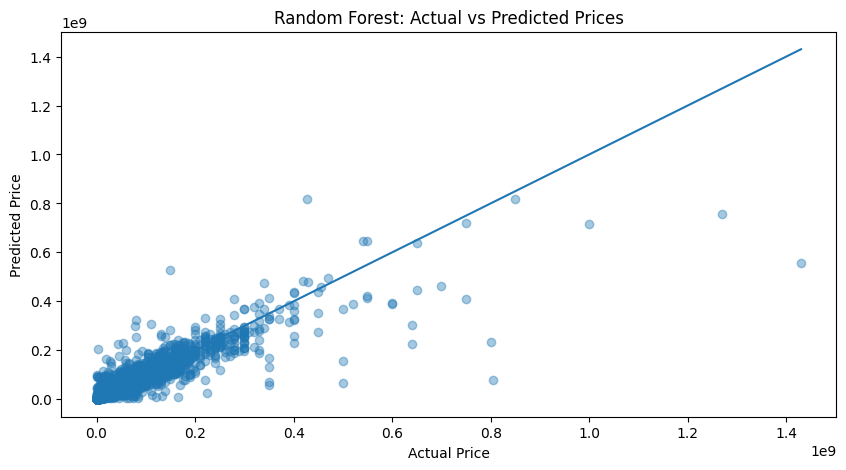

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.scatter(Y_test,Y_pred_rf,alpha=0.4)
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()]
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest: Actual vs Predicted Prices")

plt.show()

Step 13:Feature Importance

In [15]:
importance=rf_model.feature_importances_
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})
feature_importance=feature_importance.sort_values(by="Importance",ascending=False)
print(feature_importance.head(15))

                        Feature  Importance
5                    Area_Marla    0.560586
0                      latitude    0.158891
1                     longitude    0.082669
4                     Area Size    0.065015
3                      bedrooms    0.030152
10          property_type_House    0.020801
8                           day    0.020409
2                         baths    0.018447
7                         month    0.012333
33     Area Category_5-10 Kanal    0.011656
26    Area Category_15-20 Kanal    0.008099
9            property_type_Flat    0.002015
32  Area Category_400-500 Kanal    0.001253
22      Area Category_1-5 Kanal    0.001158
18              city_Rawalpindi    0.000879


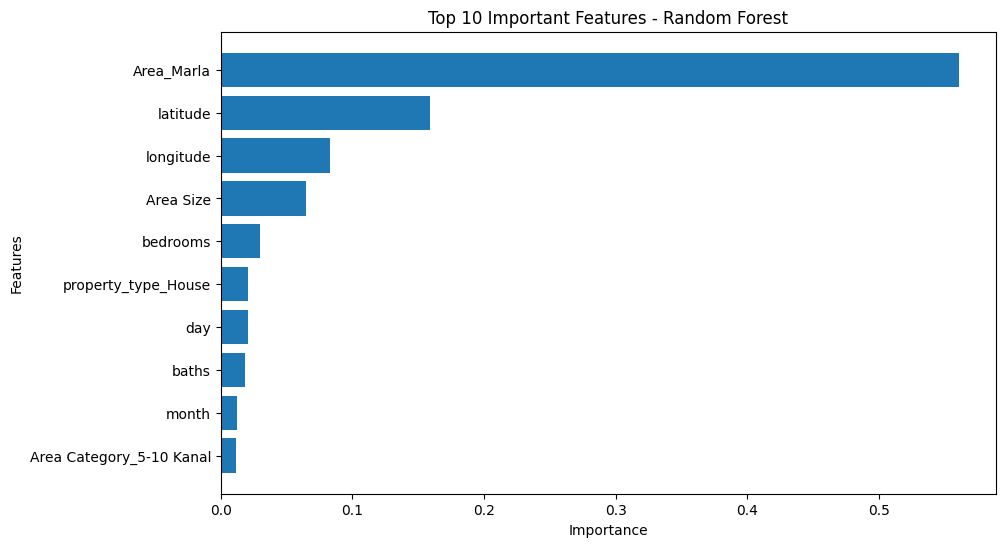

In [16]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")

plt.gca().invert_yaxis()

plt.show()

Final Step:Save the model

In [17]:
import joblib

print("Joblib installed successfully!")

Joblib installed successfully!


In [18]:
joblib.dump(rf_model, "Random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


Load & Test Saved Model 

In [19]:
import joblib

loaded_model = joblib.load("Random_forest_model.pkl")

print("Random Forest model loaded successfully!")

Random Forest model loaded successfully!


In [20]:
Y_pred_loaded = loaded_model.predict(X_test)

print("Prediction successful!")
print("First 10 predictions:")
print(Y_pred_loaded[:10])

Prediction successful!
First 10 predictions:
[14423500.         21334416.66666666 14525607.79296289 61841836.51071152
  7723224.21052631  8539535.71428571  6084600.         13124277.77777778
  4939000.          3533033.33333333]


In [21]:
import numpy as np

print(
    "Predictions match:",
    np.allclose(Y_pred_rf, Y_pred_loaded)
)

Predictions match: True


In [22]:
print("Number of model features:", loaded_model.n_features_in_)
print("Number of training features:", X_train.shape[1])
print("Feature count matches:", loaded_model.n_features_in_ == X_train.shape[1])

Number of model features: 40
Number of training features: 40
Feature count matches: True


Verify Model for final Evaluation 

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
mae_loaded=mean_absolute_error(Y_test, Y_pred_loaded)
rmse_loaded=np.sqrt(mean_squared_error(Y_test, Y_pred_loaded))
r2_loaded=r2_score(Y_test, Y_pred_loaded)
print("Loaded Random Forest Model Performance")
print("=" * 50)
print("MAE  :", mae_loaded)
print("RMSE :", rmse_loaded)
print("R²   :", r2_loaded)

Loaded Random Forest Model Performance
MAE  : 4356408.007868034
RMSE : 16100869.381539566
R²   : 0.8469327817193893


In [24]:
feature_columns = X_train.columns.tolist()

joblib.dump(feature_columns, "feature_columns.pkl")

print("Feature columns saved successfully!")
print("Number of features:", len(feature_columns))

Feature columns saved successfully!
Number of features: 40


In [25]:
import os

print("scaler.pkl exists:", os.path.exists("scaler.pkl"))
print("feature_columns.pkl exists:", os.path.exists("feature_columns.pkl"))
print("random_forest_model.pkl exists:", os.path.exists("random_forest_model.pkl"))

scaler.pkl exists: True
feature_columns.pkl exists: True
random_forest_model.pkl exists: True


Verify Saved file by loading

In [26]:
import joblib

# Load saved model
loaded_model = joblib.load("random_forest_model.pkl")

# Load saved scaler
loaded_scaler = joblib.load("scaler.pkl")

# Load feature columns
loaded_features = joblib.load("feature_columns.pkl")

print("Model loaded:", loaded_model is not None)
print("Scaler loaded:", loaded_scaler is not None)
print("Number of features:", len(loaded_features))

Model loaded: True
Scaler loaded: True
Number of features: 40


View 40 Features

In [27]:
print("Model Features:")
for i, feature in enumerate(loaded_features, start=1):
    print(i, feature)

Model Features:
1 latitude
2 longitude
3 baths
4 bedrooms
5 Area Size
6 Area_Marla
7 year
8 month
9 day
10 property_type_Flat
11 property_type_House
12 property_type_Lower Portion
13 property_type_Penthouse
14 property_type_Room
15 property_type_Upper Portion
16 city_Islamabad
17 city_Karachi
18 city_Lahore
19 city_Rawalpindi
20 province_name_Punjab
21 province_name_Sindh
22 Area Type_Marla
23 Area Category_1-5 Kanal
24 Area Category_10-15 Kanal
25 Area Category_10-15 Marla
26 Area Category_100-200 Kanal
27 Area Category_15-20 Kanal
28 Area Category_15-20 Marla
29 Area Category_20-30 Kanal
30 Area Category_200-300 Kanal
31 Area Category_30-40 Kanal
32 Area Category_40-50 Kanal
33 Area Category_400-500 Kanal
34 Area Category_5-10 Kanal
35 Area Category_5-10 Marla
36 Area Category_50-60 Kanal
37 Area Category_60-70 Kanal
38 Area Category_70-80 Kanal
39 Area Category_80-90 Kanal
40 Area Category_90-100 Kanal


Start Prediction

In [28]:
# Example new house

new_house = {
    "latitude": 31.5204,
    "longitude": 74.3587,
    "baths": 4,
    "bedrooms": 4,
    "Area Size": 10,
    "Area_Marla": 10,
    "year": 2026,
    "month": 10,
    "day": 5,
    "property_type": "House",
    "city": "Lahore",
    "province_name": "Punjab",
    "Area Type": "Marla",
    "Area Category": "5-10 Marla"
}

print(new_house)

{'latitude': 31.5204, 'longitude': 74.3587, 'baths': 4, 'bedrooms': 4, 'Area Size': 10, 'Area_Marla': 10, 'year': 2026, 'month': 10, 'day': 5, 'property_type': 'House', 'city': 'Lahore', 'province_name': 'Punjab', 'Area Type': 'Marla', 'Area Category': '5-10 Marla'}


In [29]:
import pandas as pd

# Convert new house dictionary into DataFrame
new_house_df = pd.DataFrame([new_house])

# One-hot encode categorical columns
categorical_features = [
    "property_type",
    "city",
    "province_name",
    "Area Type",
    "Area Category"
]

new_house_encoded = pd.get_dummies(
    new_house_df,
    columns=categorical_features,
    drop_first=True
)

# Add missing model features
for feature in loaded_features:
    if feature not in new_house_encoded.columns:
        new_house_encoded[feature] = 0

# Keep exactly the same 40 features and same order
new_house_encoded = new_house_encoded[loaded_features]

print("New house shape:", new_house_encoded.shape)
print("Number of features:", len(new_house_encoded.columns))

New house shape: (1, 40)
Number of features: 40


In [30]:
# Scale the new house using the saved scaler
new_house_scaled = loaded_scaler.transform(new_house_encoded)

print("Scaled new house shape:", new_house_scaled.shape)

Scaled new house shape: (1, 40)


In [31]:
# Predict house price
predicted_price = loaded_model.predict(new_house_scaled)

print("Predicted House Price:", predicted_price[0])
print("Predicted House Price (PKR):", round(predicted_price[0]))

Predicted House Price: 26194680.0
Predicted House Price (PKR): 26194680


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
